   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 48.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 39.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 73.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 49.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 70.6 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]
PennyLane version: 0.45.1
EXACT DIAGONALIZATION
Eigenvalues: [-3.  1.  1.  1.]
Exact ground-state energy: -3.0
Ground state: [ 0.        +0.j  0.70710678+0.j -0.70710678+0.j  0.        +0.j]

Evolution operator U = exp(-iHt)
Evolution time: 0.7853981633974483


/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(



IDEAL IQPE
Majority bits: [0 1 1 0]
Estimated phase: 0.375
Recovered energy: -3.0
Exact energy: -3.0
Absolute error: 0.0
Iteration k=3: bit=0, P(1)=0.0000, feedback=-0.000000
Iteration k=2: bit=1, P(1)=1.0000, feedback=-0.785398
Iteration k=1: bit=1, P(1)=0.8555, feedback=-1.178097
Iteration k=0: bit=0, P(1)=0.3030, feedback=-1.178097

NOISE-FREE MANUAL IQPE
Bits: [0 1 1 0]
Phase: 0.375
Recovered energy: -3.0
Exact energy: -3.0
Absolute error: 0.0
p= 0.0000 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.0010 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.0025 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.0050 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.0100 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.0200 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.0500 | bits=[0 1 1 0] | phase=0.37500 | energy=-3.00000 | error=0.00000
p= 0.100

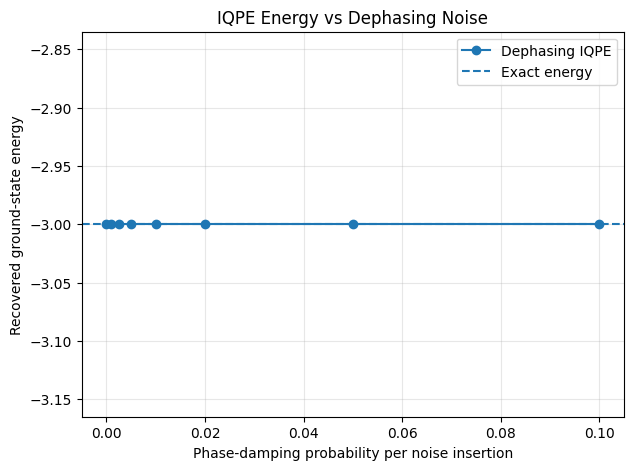

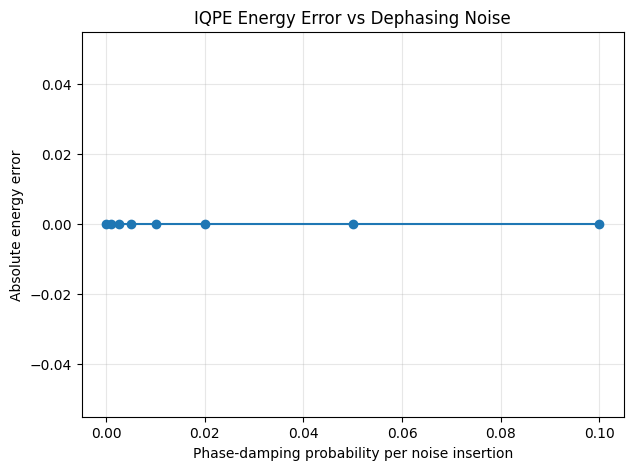

Readout p= 0.0000 | bits=[0 1 1 0] | energy=-3.00000 | error=0.00000
Readout p= 0.0050 | bits=[0 1 1 0] | energy=-3.00000 | error=0.00000
Readout p= 0.0100 | bits=[0 1 1 0] | energy=-3.00000 | error=0.00000
Readout p= 0.0200 | bits=[0 1 1 0] | energy=-3.00000 | error=0.00000
Readout p= 0.0500 | bits=[0 1 1 0] | energy=-3.00000 | error=0.00000
Readout p= 0.1000 | bits=[0 1 1 0] | energy=-3.00000 | error=0.00000


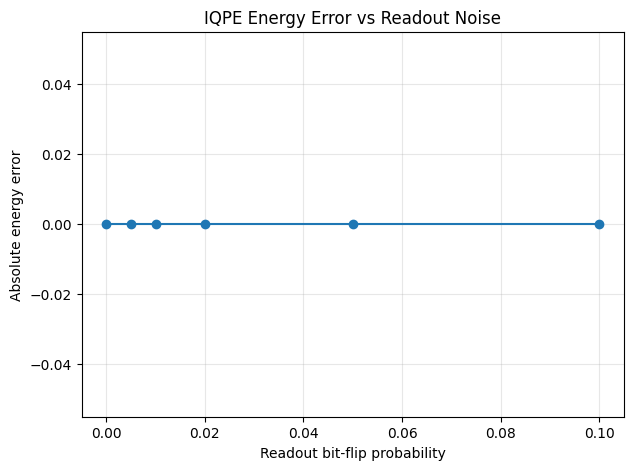

Iteration k=3: bit=0, P(1)=0.0276, feedback=-0.000000
Iteration k=2: bit=1, P(1)=0.9756, feedback=-0.785398
Iteration k=1: bit=1, P(1)=0.8322, feedback=-1.178097
Iteration k=0: bit=0, P(1)=0.3196, feedback=-1.178097

COMBINED NOISE
Bits: [0 1 1 0]
Phase: 0.375
Recovered energy: -3.0
Exact energy: -3.0
Absolute error: 0.0


In [1]:
!pip install pennylane scipy matplotlib
import pennylane as qml
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

print("PennyLane version:", qml.__version__)


# ============================================================
# 1. EXACT DIAGONALIZATION
# ============================================================

J = 1.0

H = (
    J * (qml.PauliX(0) @ qml.PauliX(1))
    + J * (qml.PauliY(0) @ qml.PauliY(1))
    + J * (qml.PauliZ(0) @ qml.PauliZ(1))
)

H_matrix = qml.matrix(H)

eigvals, eigvecs = np.linalg.eigh(H_matrix)

ground_state = eigvecs[:, 0]

print("=" * 60)
print("EXACT DIAGONALIZATION")
print("=" * 60)
print("Eigenvalues:", eigvals)
print("Exact ground-state energy:", eigvals[0])
print("Ground state:", ground_state)

# Time evolution operator
t = np.pi / 4
U = expm(-1j * H_matrix * t)

print("\nEvolution operator U = exp(-iHt)")
print("Evolution time:", t)


# ============================================================
# 2. IQPE PARAMETERS
# ============================================================

shots = 2000
n_bits = 4

# Three wires:
# Wire 0: Ancilla
# Wires 1 and 2: System qubits


# ============================================================
# 3. IDEAL IQPE
# ============================================================

ideal_dev = qml.device("default.qubit", wires=3, shots=shots)

@qml.qnode(ideal_dev)
def ideal_iqpe():

    qml.StatePrep(ground_state, wires=[1, 2])

    base = qml.QubitUnitary(U, wires=[1, 2])

    bits = qml.iterative_qpe(
        base,
        aux_wire=0,
        iters=n_bits
    )

    return qml.sample(bits)


ideal_results = ideal_iqpe()

ideal_bits = np.round(
    ideal_results.mean(axis=0)
).astype(int)

ideal_phase = sum(
    int(bit) / (2 ** (i + 1))
    for i, bit in enumerate(ideal_bits)
)

ideal_energy = -(2 * np.pi * ideal_phase) / t

print("\n" + "=" * 60)
print("IDEAL IQPE")
print("=" * 60)
print("Majority bits:", ideal_bits)
print("Estimated phase:", ideal_phase)
print("Recovered energy:", ideal_energy)
print("Exact energy:", eigvals[0])
print("Absolute error:", abs(ideal_energy - eigvals[0]))


# ============================================================
# 4. CONTROLLED UNITARY
# ============================================================

def controlled_unitary(U_matrix):

    CU = np.eye(8, dtype=complex)
    CU[4:8, 4:8] = U_matrix

    return CU


# ============================================================
# 5. DEPHASING NOISE CHANNEL
# ============================================================

def add_dephasing_noise(p):

    """
    Apply independent single-qubit phase-damping noise
    to all three wires.

    p = phase-damping probability.
    """

    if p <= 0:
        return

    for w in range(3):
        qml.PhaseDamping(p, wires=w)


# ============================================================
# 6. ONE NOISY IQPE ITERATION
# ============================================================

def noisy_iqpe_step(
    U_power,
    feedback,
    p_dephase=0.0,
    p_readout=0.0,
    shots=2000
):

    dev = qml.device(
        "default.mixed",
        wires=3,
        shots=shots
    )

    CU_power = controlled_unitary(U_power)

    @qml.qnode(dev)
    def circuit():

        # Prepare the Heisenberg ground state
        qml.StatePrep(ground_state, wires=[1, 2])
        add_dephasing_noise(p_dephase)

        # Ancilla preparation
        qml.Hadamard(0)
        add_dephasing_noise(p_dephase)

        # Controlled U^(2^k)
        qml.QubitUnitary(CU_power, wires=[0, 1, 2])
        add_dephasing_noise(p_dephase)

        # Adaptive phase-feedback rotation
        qml.RZ(feedback, wires=0)
        add_dephasing_noise(p_dephase)

        # Final Hadamard
        qml.Hadamard(0)
        add_dephasing_noise(p_dephase)

        return qml.sample(wires=0)

    samples = np.asarray(circuit()).reshape(-1)

    # Classical readout bit-flip error
    if p_readout > 0:

        rng = np.random.default_rng()

        flips = (
            rng.random(len(samples)) < p_readout
        )

        samples = np.logical_xor(
            samples.astype(int),
            flips
        ).astype(int)

    probability_one = float(np.mean(samples))

    bit = int(probability_one >= 0.5)

    return bit, probability_one, samples


# ============================================================
# 7. COMPLETE ADAPTIVE NOISY IQPE
# ============================================================

def run_noisy_iqpe(
    p_dephase=0.0,
    p_readout=0.0,
    shots=2000,
    n_bits=4,
    verbose=True
):

    bits = []
    probabilities = []

    feedback = 0.0

    for k in reversed(range(n_bits)):

        U_power = np.linalg.matrix_power(
            U,
            2 ** k
        )

        bit, p1, _ = noisy_iqpe_step(
            U_power,
            feedback,
            p_dephase=p_dephase,
            p_readout=p_readout,
            shots=shots
        )

        bits.append(bit)
        probabilities.append(p1)

        # Update adaptive phase feedback
        feedback = -np.pi * sum(
            bits[j] / (2 ** (j + 1))
            for j in range(len(bits))
        )

        if verbose:

            print(
                f"Iteration k={k}: "
                f"bit={bit}, "
                f"P(1)={p1:.4f}, "
                f"feedback={feedback:.6f}"
            )

    # Reconstruct binary phase
    phase = sum(
        bit / (2 ** (i + 1))
        for i, bit in enumerate(bits)
    )

    # Convert phase into energy
    energy = -(2 * np.pi * phase) / t

    error = abs(energy - eigvals[0])

    return {
        "bits": np.array(bits),
        "probabilities": np.array(probabilities),
        "phase": phase,
        "energy": energy,
        "error": error
    }


# ============================================================
# 8. NOISE-FREE VALIDATION
# ============================================================

noise_free = run_noisy_iqpe(
    p_dephase=0.0,
    p_readout=0.0,
    shots=2000,
    n_bits=4,
    verbose=True
)

print("\n" + "=" * 60)
print("NOISE-FREE MANUAL IQPE")
print("=" * 60)
print("Bits:", noise_free["bits"])
print("Phase:", noise_free["phase"])
print("Recovered energy:", noise_free["energy"])
print("Exact energy:", eigvals[0])
print("Absolute error:", noise_free["error"])


# ============================================================
# 9. DEPHASING NOISE SWEEP
# ============================================================

dephasing_levels = np.array([
    0.000,
    0.001,
    0.0025,
    0.005,
    0.010,
    0.020,
    0.050,
    0.100
])

sweep_shots = 2000

dephasing_energies = []
dephasing_errors = []
dephasing_phases = []
all_bits = []

for p in dephasing_levels:

    result = run_noisy_iqpe(
        p_dephase=float(p),
        p_readout=0.0,
        shots=sweep_shots,
        n_bits=4,
        verbose=False
    )

    dephasing_energies.append(result["energy"])
    dephasing_errors.append(result["error"])
    dephasing_phases.append(result["phase"])
    all_bits.append(result["bits"])

    print(
        f"p={p:7.4f} | "
        f"bits={result['bits']} | "
        f"phase={result['phase']:.5f} | "
        f"energy={result['energy']:.5f} | "
        f"error={result['error']:.5f}"
    )

dephasing_energies = np.asarray(dephasing_energies)
dephasing_errors = np.asarray(dephasing_errors)
dephasing_phases = np.asarray(dephasing_phases)


# ============================================================
# 10. PLOT: ENERGY VS DEPHASING
# ============================================================

plt.figure(figsize=(7, 5))

plt.plot(
    dephasing_levels,
    dephasing_energies,
    marker="o",
    label="Dephasing IQPE"
)

plt.axhline(
    float(eigvals[0]),
    linestyle="--",
    label="Exact energy"
)

plt.xlabel("Phase-damping probability per noise insertion")
plt.ylabel("Recovered ground-state energy")
plt.title("IQPE Energy vs Dephasing Noise")

plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


# ============================================================
# 11. PLOT: ENERGY ERROR VS DEPHASING
# ============================================================

plt.figure(figsize=(7, 5))

plt.plot(
    dephasing_levels,
    dephasing_errors,
    marker="o"
)

plt.xlabel("Phase-damping probability per noise insertion")
plt.ylabel("Absolute energy error")
plt.title("IQPE Energy Error vs Dephasing Noise")

plt.grid(True, alpha=0.3)
plt.show()


# ============================================================
# 12. OPTIONAL: READOUT-NOISE STUDY
# ============================================================

readout_levels = np.array([
    0.000,
    0.005,
    0.010,
    0.020,
    0.050,
    0.100
])

readout_energies = []
readout_errors = []

for p in readout_levels:

    result = run_noisy_iqpe(
        p_dephase=0.0,
        p_readout=float(p),
        shots=sweep_shots,
        n_bits=4,
        verbose=False
    )

    readout_energies.append(result["energy"])
    readout_errors.append(result["error"])

    print(
        f"Readout p={p:7.4f} | "
        f"bits={result['bits']} | "
        f"energy={result['energy']:.5f} | "
        f"error={result['error']:.5f}"
    )

readout_energies = np.asarray(readout_energies)
readout_errors = np.asarray(readout_errors)


# ============================================================
# 13. PLOT: READOUT ERROR
# ============================================================

plt.figure(figsize=(7, 5))

plt.plot(
    readout_levels,
    readout_errors,
    marker="o"
)

plt.xlabel("Readout bit-flip probability")
plt.ylabel("Absolute energy error")
plt.title("IQPE Energy Error vs Readout Noise")

plt.grid(True, alpha=0.3)
plt.show()


# ============================================================
# 14. COMBINED DEPHASING + READOUT NOISE
# ============================================================

combined = run_noisy_iqpe(
    p_dephase=0.01,
    p_readout=0.02,
    shots=5000,
    n_bits=4,
    verbose=True
)

print("\n" + "=" * 60)
print("COMBINED NOISE")
print("=" * 60)

print("Bits:", combined["bits"])
print("Phase:", combined["phase"])
print("Recovered energy:", combined["energy"])
print("Exact energy:", eigvals[0])
print("Absolute error:", combined["error"])
